# Tools comparison

[W: Chinese Tools GenderGuesser](https://www.chinese-tools.com/tools/gender-guesser.html)

[R: ChineseNames R package](https://cran.r-project.org/web/packages/ChineseNames/ChineseNames.pdf)

[N: Namsor](https://namsor.app/)

In [1]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios
import vis
import tools_comparison
from tools_comparison import ToolsComparison
import categorical
import constants

In [2]:
VERSION = 3

DIR_GT = f'../../data/v{VERSION}/annotations/gender'
DIR_RESULTS = f'../../results/v{VERSION}/'

DIR_NAMES = ios.path_join(DIR_RESULTS, 'names/chinese')
DIR_GENDER = ios.path_join(DIR_RESULTS, 'gender')

DIR_TOOL_W = ios.path_join(DIR_GENDER, 'tool_w')
DIR_TOOL_R = ios.path_join(DIR_GENDER, 'tool_r')
DIR_TOOL_N = ios.path_join(DIR_GENDER, 'tool_n')

DIR_PRED = ios.path_join(DIR_GENDER, 'predictions')
FN_GT = constants.FN_ANNOTATIONS

## Data

In [3]:
# Ground truth preparation (multiple files)
assert ToolsComparison.prepare_ground_truth(dir_gt=DIR_GT, fn_gt=FN_GT)

# 148 rows × 12 columns

[INFO] Found 2 files in ../../data/v3/annotations/gender.
[2025-08-13 20:50:37] Reading ../../data/v3/annotations/gender/Chinese first names gender inference (Responses) - round 2.xlsx
[INFO] ../../data/v3/annotations/gender/Chinese first names gender inference (Responses) - round 2.xlsx has 11 columns and 48 rows.
[INFO] single_char
True     46
False     2
Name: count, dtype: int64
[2025-08-13 20:50:37] Reading ../../data/v3/annotations/gender/Chinese first names gender inference (Responses).xlsx
[INFO] ../../data/v3/annotations/gender/Chinese first names gender inference (Responses).xlsx has 11 columns and 100 rows.
[INFO] single_char
False    96
True      4
Name: count, dtype: int64
[INFO] Merging 2 files into one dataframe with 148 rows and 13 columns.
[INFO] single_char
False    98
True     50
Name: count, dtype: int64


In [4]:
tc = ToolsComparison(dir_tool_w=DIR_TOOL_W, dir_tool_r=DIR_TOOL_R, dir_tool_n=DIR_TOOL_N, dir_gt=DIR_GT, dir_names=DIR_NAMES)
tc.load_data()
tc.validate_givennames()
tc.df_givennames.givenname.nunique(), tc.df_gt.givenname.nunique(), tc.df_ch_gender_n.givenname.nunique(), tc.df_ch_gender_r.givenname.nunique(), tc.df_ch_gender_w.givenname.nunique()

# (148, 46144, 46144, 38048) (8096 1 char)

(46144, 148, 46144, 46144, 38048)

In [5]:
tc.compare_unique_chinese_given_names()
tc.df_ch_genders.head(2)

(46144, 3) (46144, 3) (38048, 6)
148


,ngender_r,gender_w,a1,a2,a3,a4,a5,a6,a7,a8,...,std_ngender_rnw,std_ngender_rn,std_ngender_rw,std_ngender_nw,mode,mode_ngender_rnw,mode_ngender_rn,mode_ngender_rw,mode_ngender_nw,gender_nw
givenname,,,,,,,,,,,,,,,,,,,,,
㑇,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.464531,neutral
㑊,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.464531,neutral


In [6]:
tc.df_ch_genders.query('gt==True')[['mean','median','mode']]

,mean,median,mode
givenname,,,
东,0.159091,0.00,0.00
习,0.318182,0.25,0.25
仅,0.477273,0.50,0.50
县,0.363636,0.50,0.50
园,0.659091,0.75,0.75
...,...,...,...
雪天,0.590909,0.75,0.75
静平,0.522727,0.50,0.75
颖伶,0.909091,1.00,1.00


In [7]:
tc.save(DIR_PRED, tools_comparison.const.FN_CH_GIVEN_NAMES_GENDER)

## Overview

#### Categorical

In [8]:
FIGSIZE_SMALL = (5,3)

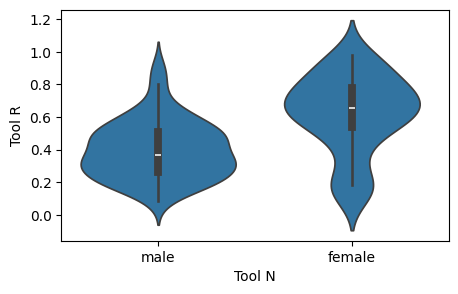

In [9]:
tool_y = 'r' # numerical
tool_x = 'n' # categorical
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool_x}', y=f'ngender_{tool_y}', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool_x.upper()}', 
                ylabel=f'Tool {tool_y.upper()}',
                )

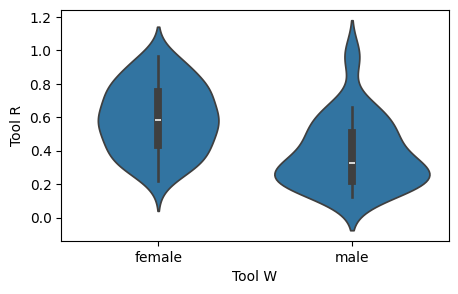

In [10]:
tool_y = 'r' # numerical
tool_x = 'w' # categorical
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool_x}', y=f'ngender_{tool_y}', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool_x.upper()}', 
                ylabel=f'Tool {tool_y.upper()}',
                )

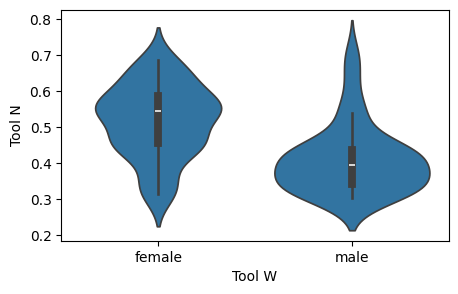

In [11]:
tool_y = 'n' # numerical
tool_x = 'w' # categorical
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool_x}', y=f'ngender_{tool_y}', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool_x.upper()}', 
                ylabel=f'Tool {tool_y.upper()}',
                )

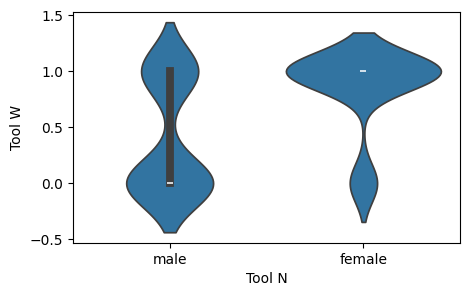

In [12]:
tool_y = 'w' # numerical
tool_x = 'n' # categorical
vis.plot_violin(df=tc.df_ch_genders_gt, x=f'gender_{tool_x}', y=f'ngender_{tool_y}', figsize=FIGSIZE_SMALL, 
                xlabel=f'Tool {tool_x.upper()}', 
                ylabel=f'Tool {tool_y.upper()}',
                )

#### Numerical

[Warning] Dropped 10 rows with NaN values
0.26040847137576534 0.3515238590431363


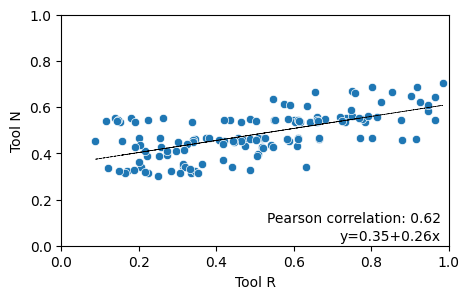

In [13]:
## scatter plot between namsor and R
tool_x = 'ngender_r'
tool_y = 'ngender_n'
vis.plot_scatter(data=tc.df_ch_genders_gt, x=tool_x, y=tool_y, figsize=(5, 3), 
                xlabel=f'Tool {tool_x.split('_')[-1].upper()}', 
                ylabel=f'Tool {tool_y.split('_')[-1].upper()}', 
                corr=True,
                fit=True,
                xlim=[0, 1], 
                ylim=[0, 1],
                )

## Index Performance

In [14]:
FIGSIZE = (5,3.1)
METRIC = 'mean' # GT

### Tool R

[Warning] Dropped 10 rows with NaN values
0.7025889568387153 0.13498133129447384


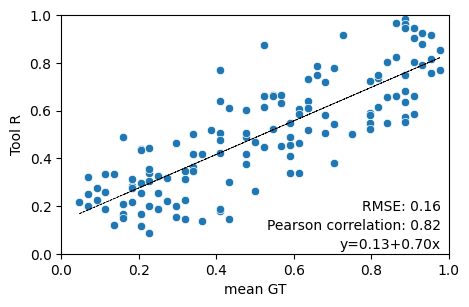

In [15]:
tool = 'r'
vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=f'ngender_{tool}', 
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'Tool {tool.upper()}', 
                 )

### Tool N

[Warning] Dropped 10 rows with NaN values
0.2578621248877783 0.3481992787189555


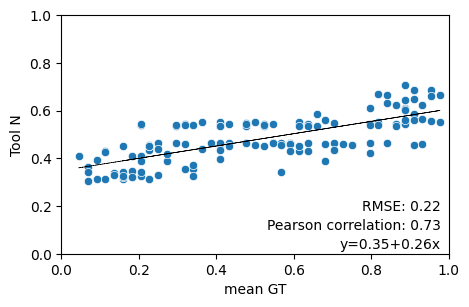

In [16]:
tool = 'n'
vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=f'ngender_{tool}', 
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'Tool {tool.upper()}', 
                 )


### Tool RNW 

[Warning] Dropped 50 rows with NaN values
0.614695371858136 0.19561808553247612


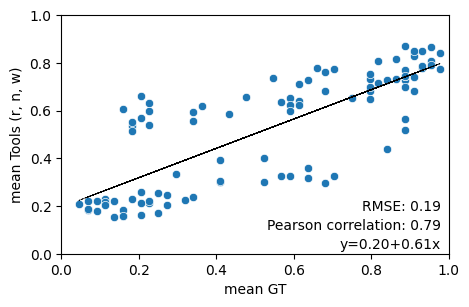

In [17]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )

### Tool RN

[Warning] Dropped 10 rows with NaN values
0.48022554086324676 0.24159030500671472


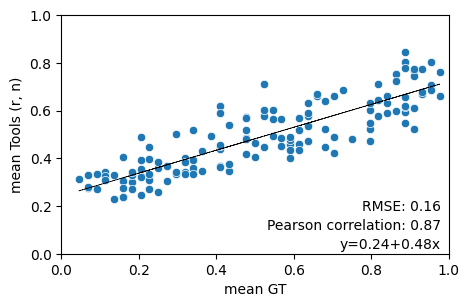

In [18]:
tools = 'rn'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )

### Tool RW

[Warning] Dropped 50 rows with NaN values
0.774293799576728 0.13535554549243206


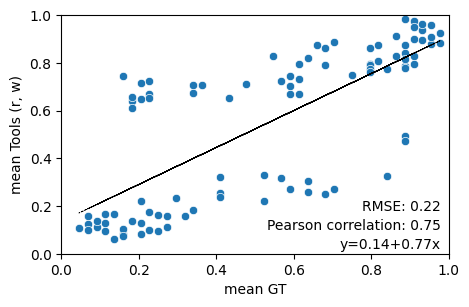

In [19]:
tools = 'rw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})', 
                 )


### Tool NW

[Warning] Dropped 50 rows with NaN values
0.5985200184471171 0.21095788839566162


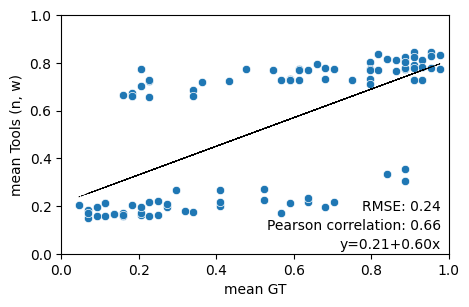

In [20]:
tools = 'nw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(data=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )

## Categorical Performance

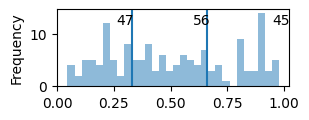

In [21]:
cuts_1 = 'mean', [0.33, 0.66]
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_1[0], bins=30, figsize=(3,1), cuts=cuts_1[1]) 

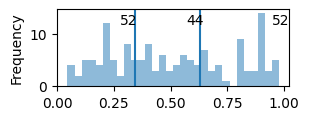

In [22]:
cuts_2 = 'mean', [0.345, 0.63]
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_2[0], bins=30, figsize=(3,1), cuts=cuts_2[1])

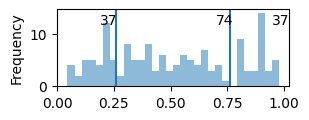

In [23]:
cuts_3 = 'mean', [0.26, 0.76]
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_3[0], bins=30, figsize=(3,1), cuts=cuts_3[1])

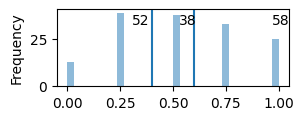

In [24]:
cuts_4 = 'median', [0.4, 0.6]
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_4[0], bins=30, figsize=(3,1), cuts=cuts_4[1])

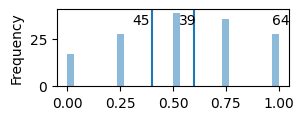

In [25]:
cuts_5 = 'mode', [0.4, 0.6]
vis.plot_distribution_and_cuts(tc.df_ch_genders_gt, cuts_5[0], bins=30, figsize=(3,1), cuts=cuts_5[1])

### Same thresholds for both GT and tools

In [26]:
STRATEGY = {1:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_1[0]}', 'cuts':cuts_1[1]},
            2:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_2[0]}', 'cuts':cuts_2[1]},
            3:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_3[0]}', 'cuts':cuts_3[1]},
            4:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_4[0]}', 'cuts':cuts_4[1]},
            5:{'name':'arbitrary_cuts', 'gt_gender':f'gender_{cuts_5[0]}', 'cuts':cuts_5[1]},
           }

In [27]:
STRATEGY_ID = 5

In [28]:

cuts = STRATEGY[STRATEGY_ID]['cuts']
gt_gender = STRATEGY[STRATEGY_ID]['gt_gender']
thresholds = [(-1,cuts[0]),(cuts[0],cuts[1]),(cuts[1],2)]
labels = categorical.GENDER_LABELS_3

df_sa = categorical.convert_numeric_to_categorical_by_thresholds(tc.df_ch_genders_gt, 
                                                                 thresholds=thresholds, 
                                                                 labels=labels)

df_comparison = categorical.comparison_metrics(df_sa,
                                               col_true=gt_gender, 
                                               labels=labels,
                                               cols_pred=['gender_r', 'gender_w', 'gender_n',
                                                          'gender_rn', 'gender_rw', 'gender_nw', 'gender_rnw',
                                                          'gender_mv_x1', 'gender_mv_x2', 'gender_mv_x1x2', 'gender_mv_all'])
df_comparison


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capita

,gender_mode,gender_r,gender_w,gender_n,gender_rn,gender_rw,gender_nw,gender_rnw,gender_mv_x1,gender_mv_x2,gender_mv_x1x2,gender_mv_all
precision,"[1.0, 1.0, 1.0]","[0.83, 0.23, 0.91]","[0.61, 0.0, 0.74]","[0.55, 0.0, 0.88]","[0.83, 0.24, 0.96]","[0.64, 0.0, 0.74]","[0.61, 0.0, 0.74]","[0.68, 0.14, 0.85]","[0.68, 0.21, 0.9]","[0.64, 0.0, 0.75]","[0.67, 0.0, 0.85]","[0.67, 0.0, 0.85]"
recall,"[1.0, 1.0, 1.0]","[0.85, 0.54, 0.59]","[0.74, 0.0, 0.82]","[0.94, 0.0, 0.69]","[0.88, 0.62, 0.53]","[0.74, 0.0, 0.82]","[0.74, 0.0, 0.82]","[0.74, 0.15, 0.78]","[0.88, 0.23, 0.71]","[0.74, 0.0, 0.86]","[0.91, 0.0, 0.86]","[0.91, 0.0, 0.86]"
f1,"[1.0, 1.0, 1.0]","[0.84, 0.33, 0.71]","[0.67, 0.0, 0.78]","[0.7, 0.0, 0.77]","[0.86, 0.34, 0.68]","[0.68, 0.0, 0.78]","[0.67, 0.0, 0.78]","[0.7, 0.15, 0.82]","[0.77, 0.22, 0.79]","[0.68, 0.0, 0.8]","[0.78, 0.0, 0.85]","[0.78, 0.0, 0.85]"
auc,"[1.0, 1.0, 1.0]","[0.88, 0.63, 0.76]","[0.74, 0.5, 0.75]","[0.77, 0.5, 0.79]","[0.89, 0.65, 0.75]","[0.76, 0.49, 0.75]","[0.74, 0.5, 0.75]","[0.77, 0.51, 0.82]","[0.83, 0.55, 0.81]","[0.76, 0.5, 0.77]","[0.84, 0.5, 0.85]","[0.84, 0.5, 0.85]"
accuracy,1.0,0.67,0.68,0.68,0.66,0.68,0.68,0.68,0.7,0.7,0.77,0.77
mean_precision,1.0,0.66,0.45,0.48,0.68,0.46,0.45,0.56,0.6,0.46,0.51,0.51
mean_recall,1.0,0.66,0.52,0.54,0.68,0.52,0.52,0.56,0.61,0.53,0.59,0.59
mean_f1,1.0,0.63,0.48,0.49,0.63,0.49,0.48,0.56,0.59,0.49,0.54,0.54
mean_auc,1.0,0.76,0.66,0.69,0.77,0.67,0.66,0.7,0.73,0.68,0.73,0.73
n_male,34,35,41,58,36,39,41,37,44,39,46,46


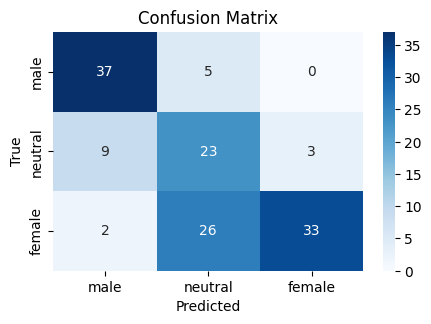

[0.77083333 0.42592593 0.91666667] [0.88095238 0.65714286 0.54098361] [0.82222222 0.51685393 0.68041237] [0.88318452 0.67808599 0.75101128] 0.6739130434782609


In [29]:
col_pred = 'gender_rn'
normalize = None

cm, precision, recall, f1, auc, accuracy = categorical.get_performance(df_sa, 
                                                                       col_true=gt_gender, 
                                                                       col_pred=col_pred, 
                                                                       labels=labels, 
                                                                       normalize=normalize)
vis.plot_confusion_matrix(cm, labels, title='Confusion Matrix', cmap='Blues', figsize=FIGSIZE)
print(precision, recall, f1, auc, accuracy)

### Different thresholds for  GT and tools

In [30]:
ys = {'r':  [0.1629132932675171, 0.7182416961523954],
      'n':  [0.33920220560098047, 0.32376522953442416],
      'rnw':[0.19485861726436837, 0.6750024992414795],
      'rn': [0.25105774943424886, 0.5210034628434099],
      'rw': [0.12268682309606231, 0.8506211340950072],
      'nw': [0.21083127926279407, 0.6533829007860216]}

y = lambda x, tool: ys[tool][0] + (ys[tool][1] * x)
new_thresholds = lambda tool, thresholds: [(y(low,tool),y(high,tool)) for (low,high) in thresholds]

In [31]:
df_eq = categorical.convert_numeric_to_categorical_by_thresholds(tc.df_ch_genders_gt, 
                                                                 thresholds=thresholds, 
                                                                 labels=labels, 
                                                                 new_trhesholds_fnc=new_thresholds,
                                                                 )

df_comparison_eq = categorical.comparison_metrics(df_eq,
                                                  col_true=gt_gender, 
                                                  labels=labels,
                                                  cols_pred=['gender_r', 'gender_w', 'gender_n',
                                                             'gender_rn', 'gender_rw', 'gender_nw', 'gender_rnw',
                                                             'gender_mv_x1', 'gender_mv_x2', 'gender_mv_x1x2', 'gender_mv_all'])
df_comparison_eq


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capita

,gender_mode,gender_r,gender_w,gender_n,gender_rn,gender_rw,gender_nw,gender_rnw,gender_mv_x1,gender_mv_x2,gender_mv_x1x2,gender_mv_all
precision,"[1.0, 1.0, 1.0]","[0.73, 0.1, 0.91]","[0.61, 0.0, 0.74]","[0.55, 0.0, 0.88]","[0.68, 0.12, 0.94]","[0.64, 0.0, 0.75]","[0.61, 0.0, 0.74]","[0.64, 0.17, 0.85]","[0.63, 0.0, 0.9]","[0.65, 0.0, 0.76]","[0.64, 0.0, 0.9]","[0.63, 0.0, 0.86]"
recall,"[1.0, 1.0, 1.0]","[0.94, 0.15, 0.59]","[0.74, 0.0, 0.82]","[0.94, 0.0, 0.69]","[0.94, 0.15, 0.65]","[0.74, 0.0, 0.82]","[0.74, 0.0, 0.82]","[0.74, 0.15, 0.78]","[0.91, 0.0, 0.71]","[0.76, 0.0, 0.86]","[0.94, 0.0, 0.84]","[0.91, 0.0, 0.82]"
f1,"[1.0, 1.0, 1.0]","[0.82, 0.12, 0.71]","[0.67, 0.0, 0.78]","[0.7, 0.0, 0.77]","[0.79, 0.14, 0.77]","[0.68, 0.0, 0.79]","[0.67, 0.0, 0.78]","[0.68, 0.16, 0.82]","[0.75, 0.0, 0.79]","[0.7, 0.0, 0.81]","[0.76, 0.0, 0.87]","[0.75, 0.0, 0.84]"
auc,"[1.0, 1.0, 1.0]","[0.88, 0.47, 0.76]","[0.74, 0.5, 0.75]","[0.77, 0.5, 0.79]","[0.85, 0.49, 0.8]","[0.76, 0.48, 0.76]","[0.74, 0.5, 0.75]","[0.76, 0.52, 0.82]","[0.82, 0.45, 0.81]","[0.77, 0.5, 0.78]","[0.83, 0.5, 0.87]","[0.82, 0.5, 0.84]"
accuracy,1.0,0.65,0.68,0.68,0.68,0.68,0.68,0.68,0.68,0.71,0.77,0.74
mean_precision,1.0,0.58,0.45,0.48,0.58,0.46,0.45,0.55,0.51,0.47,0.51,0.5
mean_recall,1.0,0.56,0.52,0.54,0.58,0.52,0.52,0.56,0.54,0.54,0.59,0.58
mean_f1,1.0,0.55,0.48,0.49,0.57,0.49,0.48,0.55,0.51,0.5,0.54,0.53
mean_auc,1.0,0.7,0.66,0.69,0.72,0.67,0.66,0.7,0.69,0.69,0.73,0.72
n_male,34,44,41,58,47,39,41,39,49,40,50,49


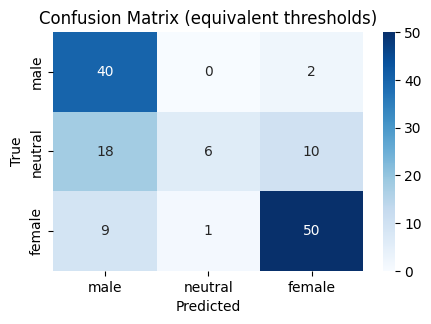

[0.59701493 0.85714286 0.80645161] [0.95238095 0.17647059 0.83333333] [0.73394495 0.29268293 0.81967213] [0.83257345 0.58333333 0.8377193 ] 0.7058823529411765


In [32]:
col_pred = 'gender_mv_x1x2'
cm, precision, recall, f1, auc, accuracy = categorical.get_performance(df_eq, 
                                                                       col_true=gt_gender, 
                                                                       col_pred=col_pred, 
                                                                       labels=labels, 
                                                                       normalize=normalize)
vis.plot_confusion_matrix(cm, labels, title='Confusion Matrix (equivalent thresholds)', cmap='Reds', figsize=FIGSIZE)
print(precision, recall, f1, auc, accuracy)

In [33]:
## Features
import setup
setup.FEATURES

Total combinations of features: 255


['ngender_r',
 'ngender_n',
 'gender_w',
 'gender_nw',
 'mean_ngender_rn',
 'mean_ngender_rw',
 'mean_ngender_nw',
 'mean_ngender_rnw']

In [34]:
from itertools import combinations

items = setup.FEATURES
all_combinations = []

# Generate combinations of different sizes
for r in range(1, len(items) + 1):
    for comb in combinations(items, r):
        # Exclude combinations that contain both "item 8" and "item 10"
        if not ("ngender_n" in comb and "gender_n" in comb):
            all_combinations.append(list(comb))

# Print the number of combinations
print("Total combinations:", len(all_combinations))

# Print all combinations
for comb in all_combinations:
    print(comb)

    # 511 total (388 without the ngender_n, gender_n)


Total combinations: 255
['ngender_r']
['ngender_n']
['gender_w']
['gender_nw']
['mean_ngender_rn']
['mean_ngender_rw']
['mean_ngender_nw']
['mean_ngender_rnw']
['ngender_r', 'ngender_n']
['ngender_r', 'gender_w']
['ngender_r', 'gender_nw']
['ngender_r', 'mean_ngender_rn']
['ngender_r', 'mean_ngender_rw']
['ngender_r', 'mean_ngender_nw']
['ngender_r', 'mean_ngender_rnw']
['ngender_n', 'gender_w']
['ngender_n', 'gender_nw']
['ngender_n', 'mean_ngender_rn']
['ngender_n', 'mean_ngender_rw']
['ngender_n', 'mean_ngender_nw']
['ngender_n', 'mean_ngender_rnw']
['gender_w', 'gender_nw']
['gender_w', 'mean_ngender_rn']
['gender_w', 'mean_ngender_rw']
['gender_w', 'mean_ngender_nw']
['gender_w', 'mean_ngender_rnw']
['gender_nw', 'mean_ngender_rn']
['gender_nw', 'mean_ngender_rw']
['gender_nw', 'mean_ngender_nw']
['gender_nw', 'mean_ngender_rnw']
['mean_ngender_rn', 'mean_ngender_rw']
['mean_ngender_rn', 'mean_ngender_nw']
['mean_ngender_rn', 'mean_ngender_rnw']
['mean_ngender_rw', 'mean_ngender_n

___

# OLD

#### Majority voting (tools)

In [ ]:
tool = 'r'
column = f'ngender_{tool}'
n_categories = 2
labels = GENDER_LABELS_2

tc.df_ch_genders_gt.loc[:,f'gender_{tool}'] = tools_comparison.pd.cut(tc.df_ch_genders_gt[column], bins=n_categories, labels=labels, right=True, precision=2, include_lowest=True)


# tc.df_ch_genders_gt.loc[:,f'majority_voting_nrw'] = tools_comparison.get_majority_voting(tc.df_ch_genders_gt, ['gender','',''], n_categories)
tc.df_ch_genders_gt.loc[:,'gender_rnw'] = tc.df_ch_genders_gt.apply(lambda row: row['gender_n'] if row['gender_n'] == row['gender_w'] and row['gender_n'] == row['gender_r'] else 
                                                                                f"mostly_{row['gender_n']}" if row['gender_n'] == row['gender_w'] else
                                                                                f"mostly_{row['gender_n']}" if row['gender_n'] == row['gender_r'] else
                                                                                f"mostly_{row['gender_r']}" if row['gender_r'] == row['gender_w'] else NEUTRAL, axis=1)

In [ ]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'

vis.plot_scatter(df=tc.df_ch_genders_gt, 
                 x=METRIC, y=column,
                 hue='gender_rnw',
                 rmse=True, corr=True, fit=True,
                 xlim=[0, 1], 
                 ylim=[0, 1],
                 figsize=FIGSIZE, xlabel=f'{METRIC} GT', ylabel=f'{METRIC} Tools ({', '.join(tools)})',
                 )


In [ ]:
# # get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=metric, labels_fnc=labels_fnc, 
                                                                                                                        bins_gt = bins_x,
                                                                                                                        bins_tools = bins_y)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=FIGSIZE)

# # plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=FIGSIZE)

# # plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=FIGSIZE)

# # plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=FIGSIZE)

### Per tool

##### Tool R

In [ ]:
column = 'ngender_r'
get_label_fnc = get_label_3classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

In [ ]:
column = 'ngender_r'
get_label_fnc = get_label_5classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

##### Tools RN

In [ ]:
tools = 'rn'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_3classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

In [ ]:
tools = 'rn'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_5classes

best_thresholds, log_auc_rmse = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

##### Tools RNW
all three

In [ ]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_3classes

best_thresholds = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)

In [ ]:
tools = 'rnw'
column = f'{METRIC}_ngender_{tools}'
get_label_fnc = get_label_5classes

best_thresholds = tc.get_best_thresholds_general(column=column, metric=METRIC, labels_fnc=get_label_fnc)
print(best_thresholds)

# get evaluation metrics
auc, precision, recall, accuracy, fpr, tpr, cm_raw, cm_recall, cm_precision, gender_labels = tc.get_performance_general(column=column, metric=METRIC, labels_fnc=get_label_fnc, thresholds=best_thresholds)

# plot roc auc
vis.plot_roc_auc(auc, fpr, tpr, gender_labels, figsize=figsize)

# plot confusion matrix (raw)
vis.plot_confusion_matrix(cm_raw, gender_labels, title='Confusion Matrix (raw)', cmap='Blues', figsize=figsize)

# plot confusion matrix (recall-row)
vis.plot_confusion_matrix(cm_recall, gender_labels, title='Confusion Matrix (recall-row)', cmap='Blues', figsize=figsize)

# plot confusion matrix (precision-col)
vis.plot_confusion_matrix(cm_precision, gender_labels, title='Confusion Matrix (precision-col)', cmap='Blues', figsize=figsize)